# Use scRICH CCC signaling modes as input for external CCC inference method

In this tutorial, we discuss how the CCC signaling modes identified via scRICH can be used as input to infer a CCC matrix using an externbal package. For this tutorial, we will use [LIANA+](https://liana-py.readthedocs.io/en/latest/), but the concept can be externded to other packages.

For this tutorial, we will consider a human dataset because LIANA+ naturally supports a human ligand/receptor databases. The approach can be extended to mouse data via LIANA+'s [homology mapping](https://liana-py.readthedocs.io/en/latest/notebooks/prior_knowledge.html#Homology-Mapping). Specifically, we will use the skin-derived organoid dataset used in Fig. 3 of the paper. This dataset is available in scRICH's github repository to reproduce this notebook.

### 0-Package import

In [1]:
import scvelo as scv
import scanpy as sc
import os
import string
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2
import scrich as ri

import liana as li
# from liana.method import singlecellsignalr, connectome, cellphonedb, natmi, logfc, cellchat, geometric_mean, rank_aggregate

In [2]:
import warnings
warnings.simplefilter("ignore", DeprecationWarning)

### 1-Load data and evaluate a CCC pathway

This dataset already includes the initial CCC pathway analysis showed in Tutorial-1, as seen by the keys in the adata.obs() dataframe.

In [3]:
adata = sc.read_h5ad('datasets/FibHSE_analyzed_moments.h5ad')

In [4]:
adata.obs.keys()

Index(['orig.ident', 'nCount_spliced', 'nFeature_spliced', 'nCount_unspliced',
       'nFeature_unspliced', 'nCount_ambiguous', 'nFeature_ambiguous',
       'spliced_snn_res.0.8', 'seurat_clusters', 'replicate',
       ...
       'SEMA7_modes', 'KIT_rec', 'KIT_lig', 'KIT_modes', 'EPHB_rec',
       'EPHB_lig', 'EPHB_modes', 'VCAM_rec', 'VCAM_lig', 'VCAM_modes'],
      dtype='object', length=135)

We focus specifically on the EGF CCC pathway:

In [5]:
adata.uns['pathways']['EGF']

{'cci_heterogeneity': array([0.52432055, 0.94259041, 0.91319071, 0.54485347, 0.70570527,
        0.574309  , 0.716206  , 0.41065311, 0.77078177, 0.30833647,
        0.918916  , 1.        ]),
 'ligands': array(['EGF', 'HBEGF', 'TGFA', 'BTC', 'EREG', 'AREG'], dtype=object),
 'receptors': array(['ERBB2', 'ERBB4', 'EGFR'], dtype=object)}

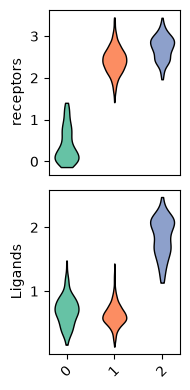

In [6]:
ri.pl.mode_violin(adata, 'EGF_modes')

Based on these profiles, we label the EGF CCC signaling modes as weak, receiver, and sender/receiver states.

In [7]:
ri.tl.rename_modes(adata, 'EGF', {0: 'Weak', 1: 'Receiver', 2: 'Sender/Receiver'})

### 2-Run LIANA+'s CCC inference

Now, we run LIANA+'s [steady state inference method](https://liana-py.readthedocs.io/en/latest/notebooks/basic_usage.html) using the EGF CCC labels rather than the cell type annotations.

In [8]:
adata.obs['EGF_modes']

AAACCCAGTGATACCT-1_3           Receiver
AAACCCATCTTAGCAG-1_3           Receiver
AAACGCTTCTATGCCC-1_3           Receiver
AAAGAACAGAGGTTTA-1_3           Receiver
AAAGAACGTACTCGTA-1_3    Sender/Receiver
                             ...       
TTTACTGCACGGGCTT-1_4               Weak
TTTCATGTCATTTCGT-1_4               Weak
TTTCCTCTCGAAGCAG-1_4               Weak
TTTCGATGTAGTCCTA-1_4           Receiver
TTTGATCGTAGACGGT-1_4               Weak
Name: EGF_modes, Length: 1509, dtype: category
Categories (3, object): ['Weak', 'Receiver', 'Sender/Receiver']

We run the "aggregate" method, which is a consensus of several CCC inference methods. Users have options to run individual methods following LIANA+'s original tutorial and documentation.

In [9]:
li.method.rank_aggregate(adata, groupby='EGF_modes', key_added='aggregate')

In [10]:
adata.uns['aggregate'].head()

,source,target,ligand_complex,receptor_complex,lr_means,cellphone_pvals,expr_prod,scaled_weight,lr_logfc,spec_weight,lrscore,specificity_rank,magnitude_rank
169,Receiver,Receiver,GSTP1,EGFR,2.281546,0.000,3.232135,0.202728,0.230967,0.164506,0.922956,0.058119,0.000149
1193,Sender/Receiver,Receiver,GSTP1,EGFR,2.132920,0.791,2.971506,-0.021826,-0.132726,0.151241,0.919913,0.654898,0.000292
1073,Sender/Receiver,Receiver,ANXA1,EGFR,2.095419,0.000,2.905744,0.664137,0.745973,0.186110,0.919084,0.005934,0.000335
1554,Sender/Receiver,Sender/Receiver,DSC2,DSG3,2.014692,0.000,4.053275,1.239888,1.236452,0.260500,0.930629,0.000396,0.000595
606,Receiver,Sender/Receiver,GSTP1,EGFR,2.159739,0.417,2.334099,-0.004830,0.025492,0.118799,0.910556,0.334721,0.000595


It is important to stress that LIANA+ will run the CCC inference model on all ligand-receptor pairs. The cell lableing "EGF_modes" computed by scRICH, however, is meaningful only for the EGF pathway. So, for exmaple, we can select only the interactions that include an EGF ligand from *adata.uns['aggregate'].head()*:

In [11]:
egf_lig, egf_rec = list(adata.uns['pathways']['EGF']['ligands']), list(adata.uns['pathways']['EGF']['receptors'])

In [12]:
egf_interactions = adata.uns['aggregate']
egf_interactions = egf_interactions[ egf_interactions['ligand_complex'].isin(egf_lig) ]

In [13]:
egf_interactions

,source,target,ligand_complex,receptor_complex,lr_means,cellphone_pvals,expr_prod,scaled_weight,lr_logfc,spec_weight,lrscore,specificity_rank,magnitude_rank
1197,Sender/Receiver,Receiver,HBEGF,CD9,1.366086,0.000,1.397170,0.363266,0.112073,0.192510,0.887340,0.021440,0.010795
1912,Sender/Receiver,Weak,HBEGF,CD9,1.251491,0.001,1.241037,0.195649,0.518258,0.170997,0.881279,0.078502,0.014827
1609,Sender/Receiver,Sender/Receiver,HBEGF,CD9,1.202853,0.160,1.174770,0.124508,-0.036309,0.161867,0.878379,0.280657,0.018176
484,Receiver,Sender/Receiver,AREG,EGFR_ERBB2,1.547944,0.000,0.685122,0.426734,0.307174,0.259316,0.846518,0.004385,0.030184
173,Receiver,Receiver,HBEGF,CD9,1.188327,0.002,0.668023,0.021510,-0.400891,0.092044,0.844869,1.000000,0.034393
2086,Weak,Receiver,HBEGF,CD9,1.170326,0.444,0.594185,-0.013098,0.127976,0.081870,0.837037,1.000000,0.043108
940,Receiver,Weak,HBEGF,CD9,1.073731,1.000,0.593372,-0.146107,0.005294,0.081758,0.836944,1.000000,0.044080
2209,Weak,Sender/Receiver,AREG,EGFR_ERBB2,1.328025,0.987,0.579609,0.203615,0.162947,0.219380,0.835336,0.132940,0.047561
610,Receiver,Sender/Receiver,HBEGF,CD9,1.025094,1.000,0.561688,-0.217248,-0.549273,0.077393,0.833165,1.000000,0.053818
1195,Sender/Receiver,Receiver,HBEGF,CD44,0.943042,0.000,0.820785,0.354861,-0.001858,0.205561,0.857891,0.145320,0.057635


Additionally, we might want to select only receptors from the EGF pathway in the "receptor_complex" column. Here, we encouter the problem that several EGF receptors are reported as complexes (such as *EGFR_ERBB2*), whereas scRICH's analysis is based on expression of individual receptors, as we see from the list of EGF-related receptors:

In [14]:
egf_rec

['ERBB2', 'ERBB4', 'EGFR']

Therefore, depending on the specific circumstance, it might be necessary to aggregate receptors into complexes. If we simply run:

In [15]:
egf_interactions_empty = egf_interactions[ egf_interactions['receptor_complex'].isin(egf_rec) ]
egf_interactions_empty

,source,target,ligand_complex,receptor_complex,lr_means,cellphone_pvals,expr_prod,scaled_weight,lr_logfc,spec_weight,lrscore,specificity_rank,magnitude_rank


we obtain an empty dataset. Instead, we select for the receptvor complex implemented in LIANA+'s CCC inference model:

In [16]:
egf_interactions = egf_interactions[ egf_interactions['receptor_complex']=='EGFR_ERBB2' ]
egf_interactions

,source,target,ligand_complex,receptor_complex,lr_means,cellphone_pvals,expr_prod,scaled_weight,lr_logfc,spec_weight,lrscore,specificity_rank,magnitude_rank
484,Receiver,Sender/Receiver,AREG,EGFR_ERBB2,1.547944,0.000,0.685122,0.426734,0.307174,0.259316,0.846518,0.004385,0.030184
2209,Weak,Sender/Receiver,AREG,EGFR_ERBB2,1.328025,0.987,0.579609,0.203615,0.162947,0.219380,0.835336,0.132940,0.047561
1495,Sender/Receiver,Sender/Receiver,AREG,EGFR_ERBB2,1.192363,1.000,0.514522,0.065979,-0.414496,0.194745,0.826979,1.000000,0.068010
1583,Sender/Receiver,Sender/Receiver,EREG,EGFR_ERBB2,0.715349,0.000,0.285661,1.119087,0.852494,0.476307,0.780769,0.000024,0.240880
53,Receiver,Receiver,AREG,EGFR_ERBB2,1.465641,0.000,0.215003,0.046392,0.101960,0.081378,0.755484,0.545851,0.249470
2024,Weak,Receiver,AREG,EGFR_ERBB2,1.245721,1.000,0.181891,-0.176728,-0.042267,0.068845,0.739709,1.000000,0.358750
1091,Sender/Receiver,Receiver,AREG,EGFR_ERBB2,1.110059,1.000,0.161466,-0.314363,-0.619711,0.061114,0.728079,1.000000,0.478185
1170,Sender/Receiver,Receiver,EREG,EGFR_ERBB2,0.633045,0.000,0.089645,0.738745,0.647279,0.149473,0.666119,0.012988,0.532342
1762,Sender/Receiver,Sender/Receiver,TGFA,EGFR_ERBB2,0.329110,0.000,0.100353,0.555783,0.199812,0.308041,0.678546,0.004385,0.601120
2256,Weak,Sender/Receiver,EREG,EGFR_ERBB2,0.296349,0.000,0.084635,0.409619,0.556571,0.141119,0.659692,0.026232,0.639587


From here, all visualization and downstream analysis implemented in LIANA+ is accessible for this data.